# SMILES: from small molecules to β-carotene

**SMILES** stands for **Simplified Molecular Input Line Entry System**. It encodes a
molecular graph as text: 

- atoms are vertices,
- bonds are edges. 

Walking through that graph produces a string; parentheses record branches and paired labels close rings. Because the same graph can be traversed in different orders, so a molecule can have many valid SMILES strings.

This notebook uses RDKit to turn strings into molecules, draw them, and inspect
their atoms, bonds, and stereochemistry. We move from small molecules to aromatic
rings and then all-trans **β-carotene** (also called beta-carotin).

A molecular formula counts elements; SMILES also specifies connectivity and can
specify stereochemistry. SMILES does **not** supply a unique 2D layout or 3D
conformation. The drawings below are generated depictions.

RDKit API examples follow its [Getting Started in Python guide](https://www.rdkit.org/docs/GettingStartedInPython.html).


In [1]:
import sys
from html import escape

from IPython.display import HTML, SVG, display
from rdkit import Chem, rdBase
from rdkit.Chem import Draw, rdMolDescriptors
from rdkit.Chem.Draw import rdMolDraw2D

print(f"Python: {sys.version.split()[0]}")
print(f"RDKit: {rdBase.rdkitVersion}")


def show_table(headers, rows):
    """Display a small table without adding a dataframe dependency."""
    head = "".join(f"<th>{escape(str(h))}</th>" for h in headers)
    body = "".join(
        "<tr>" + "".join(f"<td>{escape(str(value))}</td>" for value in row) + "</tr>"
        for row in rows
    )
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))


def show_grid(molecules, labels, per_row=3):
    display(SVG(Draw.MolsToGridImage(
        molecules, legends=labels, molsPerRow=per_row,
        subImgSize=(300, 210), useSVG=True,
    )))


Python: 3.14.7
RDKit: 2026.09.2


## 1. Reading the notation

| Syntax | Meaning | Example |
| --- | --- | --- |
| `C`, `N`, `O`, `Cl` | Element symbols; uppercase `C` is non-aromatic carbon | `CCO` (ethanol) |
| omitted bond or `-` | Usually a single bond; omitted bonds between aromatic atoms are aromatic | `CC` or `C-C` |
| `=`, `#` | Double or triple bond | `C=C`, `C#N` |
| `(...)` | Branch attached to the atom immediately before `(` | `CC(O)C` |
| matching digits | A bond between the two atoms carrying the label | `C1CCCCC1` |
| `c`, `n`, `[nH]` | Aromatic atoms; `[nH]` explicitly carries a hydrogen | `c1ccncc1` |
| `[...]` | Brackets specify atoms with charge, isotope, or explicit hydrogen information | `[NH4+]`, `[13CH4]` |
| `.` | Separate components, with no bond implied between them | `[Na+].[Cl-]` |
| `/`, `` | Directional bonds used together to encode double-bond stereochemistry | `C/C=C/C` |
| `@`, `@@` | Local tetrahedral stereochemistry, relative to traversal order | `N[C@@H](C)C(=O)O` |

Many hydrogens are implicit: 

- `C` alone represents methane, CH₄, 
- `O` alone represents water, H₂O. 

RDKit infers hydrogen counts using its valence rules. Brackets do not mean “optional”;  for example, the charge and hydrogen count in `[NH4+]` are explicit. See the [OpenSMILES specification](https://opensmiles.org/opensmiles.html) for the grammar and exceptions.


## 2. Simple molecules: chains, branches, and bond orders

Read ethanol (`CCO`) as carbon → carbon → oxygen. In acetic acid (`CC(=O)O`), the middle carbon is
bonded to the first carbon, double-bonded to a branch oxygen, and single-bonded
to the final oxygen.

A drawing uses skeletal notation: unlabeled corners and line ends represent
carbon, and most hydrogens attached to carbon are omitted. Atom and bond counts
below describe RDKit's graph, which normally omits separate hydrogen vertices.


Molecule,Input SMILES,Formula,Graph atoms,Graph bonds
Methane,C,CH4,1,0
Water,O,H2O,1,0
Ethane,CC,C2H6,2,1
Ethanol,CCO,C2H6O,3,2
Dimethyl ether,COC,C2H6O,3,2
Propan-2-ol,CC(O)C,C3H8O,4,3
Ethene,C=C,C2H4,2,1
Hydrogen cyanide,C#N,CHN,2,1
Acetic acid,CC(=O)O,C2H4O2,4,3


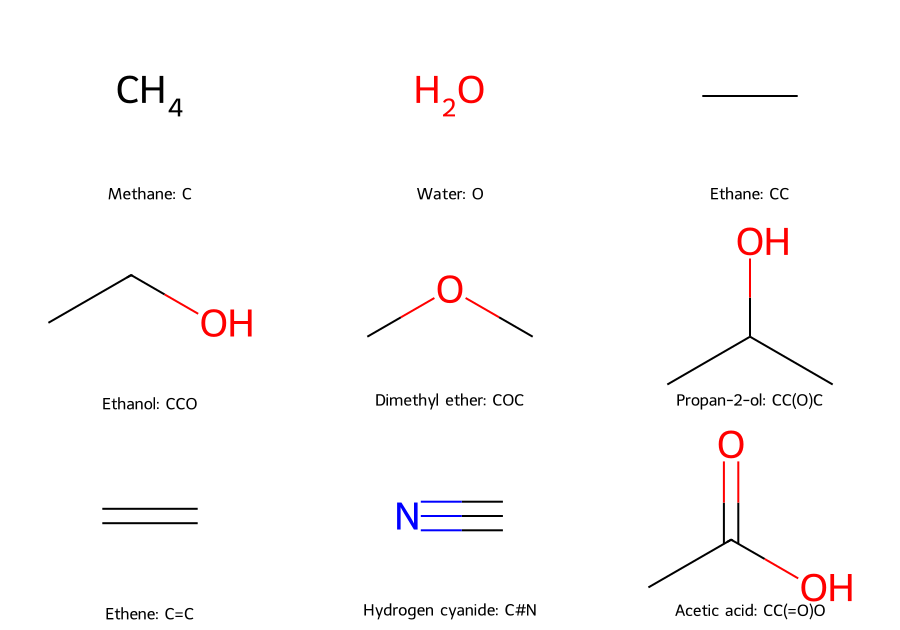

In [2]:
simple_examples = [
    ("Methane", "C"),
    ("Water", "O"),
    ("Ethane", "CC"),
    ("Ethanol", "CCO"),
    ("Dimethyl ether", "COC"),
    ("Propan-2-ol", "CC(O)C"),
    ("Ethene", "C=C"),
    ("Hydrogen cyanide", "C#N"),
    ("Acetic acid", "CC(=O)O"),
]
simple_mols = [Chem.MolFromSmiles(smiles) for _, smiles in simple_examples]
show_table(
    ["Molecule", "Input SMILES", "Formula", "Graph atoms", "Graph bonds"],
    [(name, smiles, rdMolDescriptors.CalcMolFormula(mol), mol.GetNumAtoms(), mol.GetNumBonds())
     for (name, smiles), mol in zip(simple_examples, simple_mols)],
)
show_grid(simple_mols, [f"{name}: {smiles}" for name, smiles in simple_examples])


Ethanol and dimethyl ether both have formula C₂H₆O, but their atoms connect
differently. A formula alone cannot distinguish these constitutional isomers.

Compare ethanol (top row) and dimethyl ether (bottom row), each with implicit
hydrogens (left) and explicit hydrogen atoms (right). Ethanol has an O–H bond;
in dimethyl ether, oxygen connects the two carbons and has no attached hydrogen. The atom indices in these drawings are RDKit indices, **not** SMILES ring
closure labels.


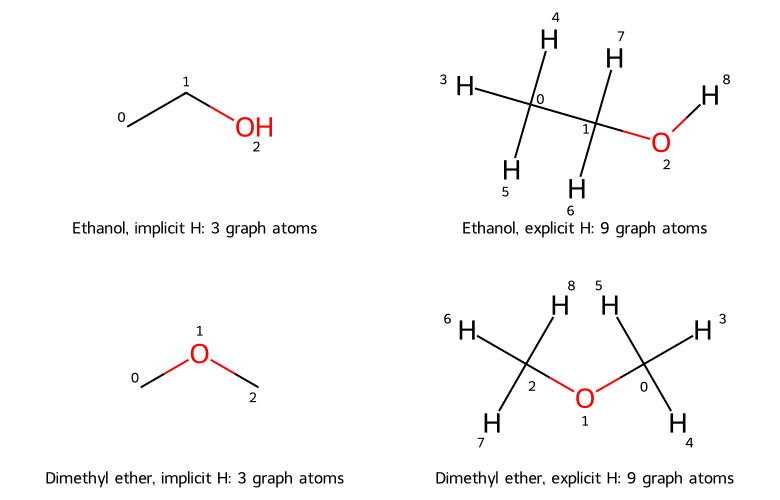

Atom index,Element,Attached H count
0,C,3
1,C,2
2,O,1


In [3]:
ethanol = Chem.MolFromSmiles("CCO")
ether = Chem.MolFromSmiles("COC")
assert rdMolDescriptors.CalcMolFormula(ethanol) == rdMolDescriptors.CalcMolFormula(ether)
assert Chem.MolToSmiles(ethanol) != Chem.MolToSmiles(ether)

ethanol_with_h = Chem.AddHs(ethanol)
ether_with_h = Chem.AddHs(ether)
options = rdMolDraw2D.MolDrawOptions()
options.addAtomIndices = True
display(SVG(Draw.MolsToGridImage(
    [ethanol, ethanol_with_h, ether, ether_with_h],
    legends=[
        "Ethanol, implicit H: 3 graph atoms",
        "Ethanol, explicit H: 9 graph atoms",
        "Dimethyl ether, implicit H: 3 graph atoms",
        "Dimethyl ether, explicit H: 9 graph atoms",
    ],
    molsPerRow=2, subImgSize=(390, 250), useSVG=True, drawOptions=options,
)))
show_table(
    ["Atom index", "Element", "Attached H count"],
    [(atom.GetIdx(), atom.GetSymbol(), atom.GetTotalNumHs()) for atom in ethanol.GetAtoms()],
)

## 3. Rings and aromaticity

In `C1CCCCC1`, create six carbons along a path and then connect the last carbon
back to the first using the matching `1` labels. `C2CCCCC2` describes the
same cyclohexane. Labels can be reused after a closure is complete.

Cyclohexane is saturated and cyclohexene has one double bond. Benzene is aromatic (e.g, it contains covalent bonds where π electrons are delocalized, leading to extra stability. See [IUPAC Gold Book](https://goldbook.iupac.org/terms/view/A00441) for details). In SMILES,
Benzene (`c1ccccc1`) is represented with lowercase (e.g, aromatic) carbons, whereas `C1=CC=CC=C1` represents the Kekulé encoding.

Pyridine uses aromatic `n`; pyrrole uses `[nH]` for the aromatic nitrogen carrying
a hydrogen. Naphthalene demonstrates fused rings and two closure labels. RDKit
assigns aromaticity using a [defined aromaticity model](https://www.rdkit.org/docs/RDKit_Book.html#aromaticity);
being cyclic or having a double bond does not by itself make a molecule aromatic.


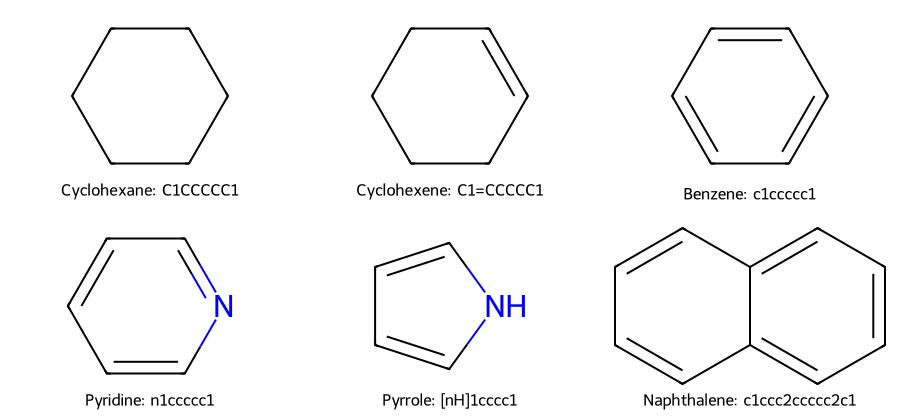

Molecule,Formula,Rings (RDKit SSSR),Aromatic atoms
Cyclohexane,C6H12,1,0
Cyclohexene,C6H10,1,0
Benzene,C6H6,1,6
Pyridine,C5H5N,1,6
Pyrrole,C4H5N,1,5
Naphthalene,C10H8,2,10


Benzene, aromatic SMILES: c1ccccc1
Benzene, Kekulé SMILES:  C1=CC=CC=C1


In [8]:
ring_examples = [
    ("Cyclohexane", "C1CCCCC1"),
    ("Cyclohexene", "C1=CCCCC1"),
    ("Benzene", "c1ccccc1"),
    ("Pyridine", "n1ccccc1"),
    ("Pyrrole", "[nH]1cccc1"),
    ("Naphthalene", "c1ccc2ccccc2c1"),
]
ring_mols = [Chem.MolFromSmiles(smiles) for _, smiles in ring_examples]
show_grid(ring_mols, [f"{name}: {smiles}" for name, smiles in ring_examples])
show_table(
    ["Molecule", "Formula", "Rings (RDKit SSSR)", "Aromatic atoms"],
    [(name, rdMolDescriptors.CalcMolFormula(mol), mol.GetRingInfo().NumRings(),
      sum(atom.GetIsAromatic() for atom in mol.GetAtoms()))
     for (name, _), mol in zip(ring_examples, ring_mols)],
)

benzene = Chem.MolFromSmiles("c1ccccc1")
assert Chem.MolToSmiles(Chem.MolFromSmiles("C1=CC=CC=C1")) == Chem.MolToSmiles(benzene)
assert Chem.MolToSmiles(Chem.MolFromSmiles("C2CCCCC2")) == Chem.MolToSmiles(ring_mols[0])
print("Benzene, aromatic SMILES:", Chem.MolToSmiles(benzene))
print("Benzene, Kekulé SMILES: ", Chem.MolToSmiles(benzene, kekuleSmiles=True))
assert all(atom.GetIsAromatic() for atom in benzene.GetAtoms())

## 4. Double-bond geometry

But-2-ene can have multiple configurations:

- `C/C=C/C` specifies the E (trans) isomer
- while `C/C=C\C` the Z (cis) isomer. 

`CC=CC` leaves this geometry unspecified. `/` and `` describe
bond directions relative to the traversal; RDKit derives the double-bond stereochemistry from them.

This influences the β-carotene's long chain: a connectivity-only string cannot tell
us which geometric isomer we have. See the [OpenSMILES bond stereochemistry rules](https://opensmiles.org/opensmiles.html#bond_stereochemistry).


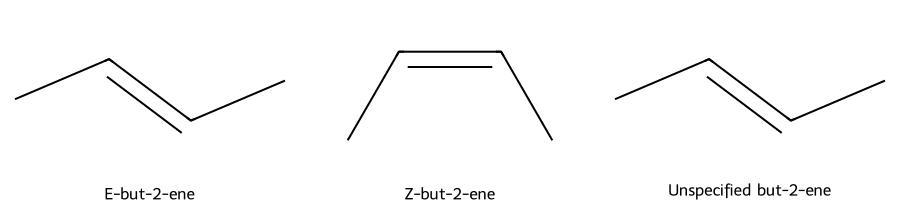

Input SMILES,Double-bond stereo,Canonical isomeric SMILES
C/C=C/C,STEREOE,C/C=C/C
C/C=C\C,STEREOZ,C/C=C\C
CC=CC,STEREONONE,CC=CC


In [7]:
stereo_examples = [
    ("E-but-2-ene", "C/C=C/C"),
    ("Z-but-2-ene", r"C/C=C\C"),
    ("Unspecified but-2-ene", "CC=CC"),
]
# A raw Python string preserves the backslash in a SMILES string.
stereo_mols = [Chem.MolFromSmiles(smiles) for _, smiles in stereo_examples]
show_grid(stereo_mols, [name for name, _ in stereo_examples])
show_table(
    ["Input SMILES", "Double-bond stereo", "Canonical isomeric SMILES"],
    [(smiles, ", ".join(str(b.GetStereo()) for b in mol.GetBonds()
                        if b.GetBondType() == Chem.BondType.DOUBLE),
      Chem.MolToSmiles(mol, isomericSmiles=True))
     for (_, smiles), mol in zip(stereo_examples, stereo_mols)],
)
assert len({Chem.MolToSmiles(m) for m in stereo_mols}) == 3
assert len({Chem.MolToSmiles(m, isomericSmiles=False) for m in stereo_mols}) == 1

## 5. All-trans β-carotene

We use the stereospecified SMILES for [PubChem CID 5280489](https://pubchem.ncbi.nlm.nih.gov/compound/5280489). This record has formula **C₄₀H₅₆** and InChIKey `OENHQHLEOONYIE-JLTXGRSLSA-N`.

It has two six-membered end rings and a connecting polyene chain. Its 11 double bonds form a conjugated system. Each double bond consists of a σ bond, which connects the carbon atoms along their internuclear axis, and a π bond, formed by sideways overlap of their p orbitals. Along the conjugated sequence, neighboring p orbitals overlap across the intervening single bonds too, allowing π electrons to spread over an extended region. This conjugation enables β-carotene to absorb visible light, giving it its orange color.


| Feature in the string | Structural meaning |
| --- | --- |
| `C1...CCC1` and `C2...CCCC2` | Close the two end rings |
| `(C)` branches | Methyl (CH₃) groups attached to the current atom |
| `C=C` repeated along the chain | Carbon–carbon double bonds |
| `/` and `\` around the chain double bonds | Specify the all-trans geometry |
| Uppercase `C` | Non-aromatic carbon atoms |

“All-trans” refers to the nine stereospecified chain double bonds. The two ring double bonds are constrained within their six-membered rings and are not assigned E/Z stereo here.


Input SMILES:
CC1=C(C(CCC1)(C)C)/C=C/C(=C/C=C/C(=C/C=C/C=C(/C=C/C=C(/C=C/C2=C(CCCC2(C)C)C)\C)\C)/C)/C

RDKit canonical isomeric SMILES:
CC1=C(/C=C/C(C)=C/C=C/C(C)=C/C=C/C=C(C)/C=C/C=C(C)/C=C/C2=C(C)CCCC2(C)C)C(C)(C)CCC1


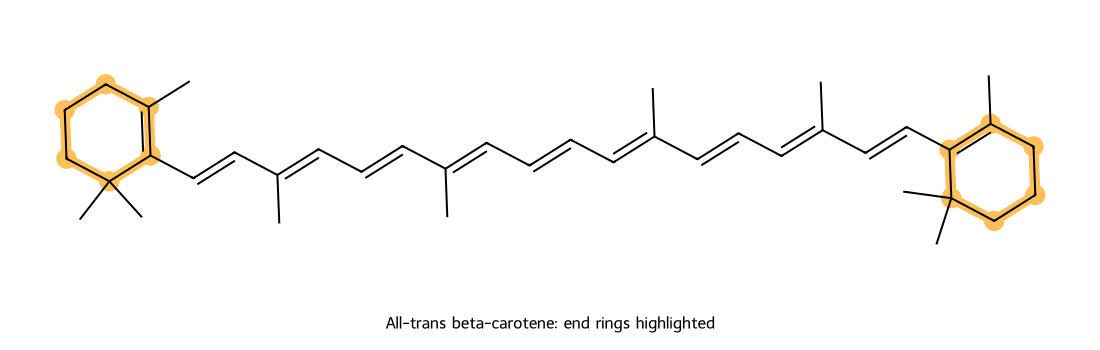

In [9]:
# Source: PubChem CID 5280489, property "SMILES" (stereospecified).
# Raw string: each backslash below is a literal SMILES character.
beta_carotene_smiles = r"CC1=C(C(CCC1)(C)C)/C=C/C(=C/C=C/C(=C/C=C/C=C(/C=C/C=C(/C=C/C2=C(CCCC2(C)C)C)\C)\C)/C)/C"
beta_carotene = Chem.MolFromSmiles(beta_carotene_smiles)
print("Input SMILES:")
print(beta_carotene_smiles)
print("\nRDKit canonical isomeric SMILES:")
print(Chem.MolToSmiles(beta_carotene, isomericSmiles=True))

# Highlight ring atoms in orange; the intervening chain remains unhighlighted.
ring_atoms = sorted({idx for ring in beta_carotene.GetRingInfo().AtomRings() for idx in ring})
ring_bonds = [bond.GetIdx() for bond in beta_carotene.GetBonds() if bond.IsInRing()]
orange = (1.0, 0.75, 0.35)
drawer = rdMolDraw2D.MolDraw2DSVG(1100, 350)
rdMolDraw2D.PrepareAndDrawMolecule(
    drawer, beta_carotene, legend="All-trans beta-carotene: end rings highlighted",
    highlightAtoms=ring_atoms, highlightBonds=ring_bonds,
    highlightAtomColors={idx: orange for idx in ring_atoms},
    highlightBondColors={idx: orange for idx in ring_bonds},
)
drawer.FinishDrawing()
display(SVG(drawer.GetDrawingText()))


In [10]:
double_bonds = [b for b in beta_carotene.GetBonds() if b.GetBondType() == Chem.BondType.DOUBLE]
chain_double_bonds = [b for b in double_bonds if not b.IsInRing()]
formula = rdMolDescriptors.CalcMolFormula(beta_carotene)
hydrogens = sum(a.GetTotalNumHs() for a in beta_carotene.GetAtoms())
aromatic_atoms = sum(a.GetIsAromatic() for a in beta_carotene.GetAtoms())

show_table(["Property", "RDKit result"], [
    ("Formula", formula),
    ("Carbon atoms", beta_carotene.GetNumAtoms()),
    ("Hydrogens (implicit + attached explicit)", hydrogens),
    ("Rings", beta_carotene.GetRingInfo().NumRings()),
    ("Double bonds (total)", len(double_bonds)),
    ("Double bonds outside rings", len(chain_double_bonds)),
    ("Aromatic atoms", aromatic_atoms),
    ("Chain double-bond stereo", ", ".join(str(b.GetStereo()) for b in chain_double_bonds)),
])

# Check both gross composition and the geometry encoded in the string.
assert formula == "C40H56"
assert beta_carotene.GetNumAtoms() == 40
assert hydrogens == 56
assert beta_carotene.GetRingInfo().NumRings() == 2
assert sorted(map(len, beta_carotene.GetRingInfo().AtomRings())) == [6, 6]
assert len(double_bonds) == 11
assert aromatic_atoms == 0
assert len(chain_double_bonds) == 9
assert all(b.GetStereo() == Chem.BondStereo.STEREOE for b in chain_double_bonds)
assert Chem.MolToInchiKey(beta_carotene) == "OENHQHLEOONYIE-JLTXGRSLSA-N"
print("Composition, ring structure, and all-trans identity checks passed.")


Property,RDKit result
Formula,C40H56
Carbon atoms,40
Hydrogens (implicit + attached explicit),56
Rings,2
Double bonds (total),11
Double bonds outside rings,9
Aromatic atoms,0
Chain double-bond stereo,"STEREOE, STEREOE, STEREOE, STEREOE, STEREOE, STEREOE, STEREOE, STEREOE, STEREOE"


Composition, ring structure, and all-trans identity checks passed.


A useful formula cross-check is the degree of unsaturation. For this hydrocarbon,
(2 × 40 + 2 − 56) / 2 = **13**: two rings plus eleven double bonds.
That count alone would not identify the molecule or its geometry.

Compare stereospecified and connectivity-only output below. Both retain the same
carbon skeleton; removing stereochemical information loses the all-trans identity.
Parsing and writing the isomeric form should preserve that information even if
RDKit changes the traversal and therefore the visible order of characters.


In [11]:
isomeric = Chem.MolToSmiles(beta_carotene, isomericSmiles=True)
connectivity_only = Chem.MolToSmiles(beta_carotene, isomericSmiles=False)
print("With geometry:", isomeric)
print("Without geometry:", connectivity_only)

round_trip = Chem.MolFromSmiles(isomeric)
assert Chem.MolToSmiles(round_trip, isomericSmiles=True) == isomeric
unspecified = Chem.MolFromSmiles(connectivity_only)
assert all(b.GetStereo() == Chem.BondStereo.STEREONONE for b in unspecified.GetBonds())
assert (2 * 40 + 2 - hydrogens) // 2 == 2 + len(double_bonds)

With geometry: CC1=C(/C=C/C(C)=C/C=C/C(C)=C/C=C/C=C(C)/C=C/C=C(C)/C=C/C2=C(C)CCCC2(C)C)C(C)(C)CCC1
Without geometry: CC(C=CC=C(C)C=CC1=C(C)CCCC1(C)C)=CC=CC=C(C)C=CC=C(C)C=CC1=C(C)CCCC1(C)C


## 6. Parsing errors and experiments

A string must satisfy syntax and RDKit's chemical validation. An unclosed ring
(`C1CC`) or an overbonded neutral carbon (`C(C)(C)(C)(C)C`) fails parsing;
`MolFromSmiles` returns `None`. Note that successful parsing does not mean that a
molecule is neither stable, synthesizable, nor biologically useful.


In [13]:
invalid_examples = ["C1CC", "C(C)(C)(C)(C)C"]
# Suppress the expected diagnostic logs only during this demonstration.
with rdBase.BlockLogs():
    invalid_results = [Chem.MolFromSmiles(smiles) for smiles in invalid_examples]
show_table(["Invalid SMILES", "Parser result"], zip(invalid_examples, invalid_results))
assert all(mol is None for mol in invalid_results)


Invalid SMILES,Parser result
C1CC,None
C(C)(C)(C)(C)C,None


Try changing the string in the next cell and predict the formula before running it:

1. Compare `CCCO` with `CC(O)C`. Which atoms connect to the oxygen?
2. Compare `C1CCCCC1`, `C1=CCCCC1`, and `c1ccccc1`. What changes in the hydrogen count?
3. Replace `c1ccccc1` with `Cc1ccccc1`. Which atom belongs to the methyl branch?
4. Revisit β-carotene: why would replacing its carbon symbols with lowercase `c` be incorrect?

Input: Cc1ccccc1
Formula: C7H8
Canonical SMILES: Cc1ccccc1
Aromatic atoms: 6


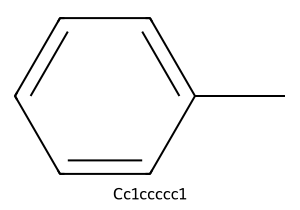

In [27]:
try_smiles = "Cc1ccccc1"
try_mol = Chem.MolFromSmiles(try_smiles)
print("Input:", try_smiles)
print("Formula:", rdMolDescriptors.CalcMolFormula(try_mol))
print("Canonical SMILES:", Chem.MolToSmiles(try_mol))
print("Aromatic atoms:", sum(a.GetIsAromatic() for a in try_mol.GetAtoms()))
show_grid([try_mol], [try_smiles], per_row=1)

## References

- [RDKit: Getting Started in Python](https://www.rdkit.org/docs/GettingStartedInPython.html) — reading, writing, and drawing molecules.
- [RDKit Book: Aromaticity](https://www.rdkit.org/docs/RDKit_Book.html#aromaticity) — RDKit's aromaticity rules.
- [OpenSMILES specification](https://opensmiles.org/opensmiles.html) — atom, bond, branch, ring, and stereochemical syntax.
- [PubChem: β-carotene, CID 5280489](https://pubchem.ncbi.nlm.nih.gov/compound/5280489) — reference structure, formula, and stereospecified SMILES.
